# Exploratory analysis: D1, D2, D3 and the dating messages

This notebook covers the two training sets, D1 (toxic conversations) and D3 (gaslighting), the extra toxic test set D2 (Jigsaw), and compares them with our dating messages. It shows counts and charts and no raw D1 or D2 comments, because both contain offensive language. The D3 examples are short and contain no slurs.

All D1 and D3 counts use the same loaders as the models (`load_d1_train_val`, `load_d3_splits`), so they describe the data each model saw.

In [ ]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from red_flag_detector.data import (
    deduplicate, load_d1_train_val, load_d3_splits, load_gaslighting, load_stress_test, load_toxic_conversations,
)
from red_flag_detector.plots import AQUA, BLUE, MUTED, ORANGE, apply_style, save

apply_style()
pd.set_option("display.max_colwidth", 120)
root = Path.cwd().parent
results = root / "results"

d1_raw_train = load_toxic_conversations("train")
d1_raw_test = load_toxic_conversations("test")
d1_train, d1_val = load_d1_train_val()
d3_train, d3_val, d3_test = load_d3_splits(root / "data" / "raw" / "gaslighting")
stress = load_stress_test(root / "data" / "dating_stress_test.csv")

## Size, class balance and cleaning

In [ ]:
d1_dedup = deduplicate(d1_raw_train)
d1_in_test = d1_dedup["text"].str.lower().isin(set(d1_raw_test["text"].str.lower()))
d3_raw_train = load_gaslighting([root / "data" / "raw" / "gaslighting" / f"{p}_train.json" for p in ("gaslighting", "anti_gaslighting")])

overview = pd.DataFrame({
    "D1 official train": [len(d1_raw_train), d1_raw_train["label"].mean()],
    "D1 after dedup": [len(d1_dedup), d1_dedup["label"].mean()],
    "D1 our train sample": [len(d1_train), d1_train["label"].mean()],
    "D1 our validation": [len(d1_val), d1_val["label"].mean()],
    "D1 official test": [len(d1_raw_test), d1_raw_test["label"].mean()],
    "D3 train": [len(d3_train), d3_train["label"].mean()],
    "D3 validation": [len(d3_val), d3_val["label"].mean()],
    "D3 test": [len(d3_test), d3_test["label"].mean()],
    "Dating messages": [len(stress), stress["label"].mean()],
}, index=["messages", "harmful share"]).T
overview["messages"] = overview["messages"].astype(int)
overview["harmful share"] = overview["harmful share"].round(3)
print(f"D1: {len(d1_raw_train) - len(d1_dedup):,} duplicate or conflicting texts removed; "
      f"{int(d1_in_test.sum()):,} train texts also in the official test removed")
print(f"D3: {len(d3_raw_train) - len(d3_train)} train texts removed (duplicates or copies of validation/test texts)")
print(f"D3 chats per split: train {d3_train.chat_id.nunique():,}, validation {d3_val.chat_id.nunique()}, "
      f"test {d3_test.chat_id.nunique()}; chats shared between train and validation: "
      f"{len(set(d3_train.chat_id) & set(d3_val.chat_id))}")
overview

D1: 28,002 duplicate or conflicting texts removed; 974 train texts also in the official test removed
D3: 47 train texts removed (duplicates or copies of validation/test texts)
D3 chats per split: train 1,752, validation 124, test 124; chats shared between train and validation: 0


,messages,harmful share
D1 official train,1754874,0.080
D1 after dedup,1726872,0.080
D1 our train sample,100000,0.080
D1 our validation,20000,0.080
D1 official test,50000,0.079
D3 train,24181,0.500
D3 validation,1688,0.500
D3 test,1720,0.500
Dating messages,120,0.500


D1 is imbalanced: 8% of messages are toxic, so always answering "not toxic" reaches 92% accuracy with an F1 of 0. That is why we report F1 for the harmful class and use class weights in every loss. D3 is balanced by design, and so is our dating set at 50%. Neither matches a real chat, where most messages are harmless.

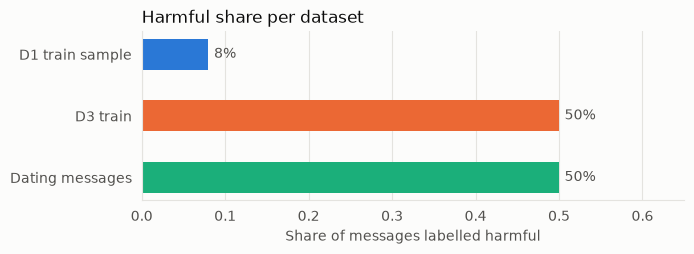

In [ ]:
shares = overview.loc[["D1 our train sample", "D3 train", "Dating messages"], "harmful share"]
fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(["D1 train sample", "D3 train", "Dating messages"][::-1], shares.values[::-1], color=[AQUA, ORANGE, BLUE], height=0.5)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in shares.values[::-1]], padding=4, color=MUTED)
ax.set_xlim(0, 0.65)
ax.set_xlabel("Share of messages labelled harmful")
ax.set_title("Harmful share per dataset")
ax.grid(axis="y", visible=False)
save(fig, results / "eda_harmful_share.png")

## Message length

,median words,75th percentile,max
D1 not toxic,36.0,73.0,209.0
D1 toxic,34.0,64.0,201.0
D3 safe,16.0,20.0,62.0
D3 gaslighting,22.0,26.0,75.0
Dating messages,9.0,10.0,15.0


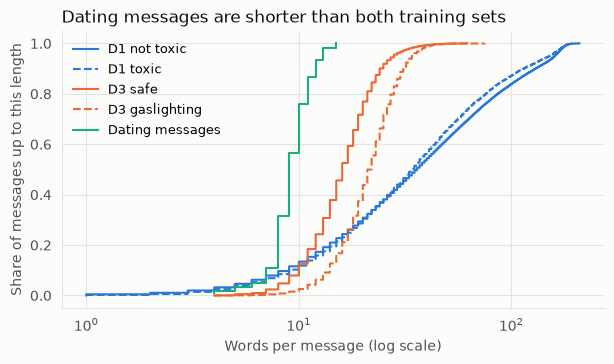

In [ ]:
def words(texts):
    return texts.str.split().str.len().to_numpy()

groups = {
    "D1 not toxic": (words(d1_train.loc[d1_train.label == 0, "text"]), BLUE, "-"),
    "D1 toxic": (words(d1_train.loc[d1_train.label == 1, "text"]), BLUE, "--"),
    "D3 safe": (words(d3_train.loc[d3_train.label == 0, "text"]), ORANGE, "-"),
    "D3 gaslighting": (words(d3_train.loc[d3_train.label == 1, "text"]), ORANGE, "--"),
    "Dating messages": (words(stress["text"]), AQUA, "-"),
}
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, (lengths, colour, style) in groups.items():
    values = np.sort(lengths)
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=colour, linestyle=style, label=name)
ax.set_xscale("log")
ax.set_xlabel("Words per message (log scale)")
ax.set_ylabel("Share of messages up to this length")
ax.set_title("Dating messages are shorter than both training sets")
ax.legend(frameon=False, fontsize=9)
save(fig, results / "eda_message_length.png")
pd.DataFrame({name: pd.Series(v[0]).describe()[["50%", "75%", "max"]] for name, v in groups.items()}).T.rename(
    columns={"50%": "median words", "75%": "75th percentile"})

Dating messages have a median of 9 words. D1 comments run about four times longer, and D3 assistant turns about twice as long. A model trained on long comments sees less evidence per dating message. Long D1 comments also get cut: DistilBERT reads at most 128 tokens, and 16% of the D1 training sample is longer than that (see `results/distilbert_finetuned_d1/metrics.json`).

## D3: the two classes differ in style

In D3 the gaslighting assistant asks probing questions and the safe assistant reassures. A model can score well on D3 by detecting questions, but that cue is nearly absent from our dating messages.

D3 safe                  0.13
D3 gaslighting           0.80
Dating: harmless         0.15
Dating: gaslighting      0.10
Dating: other harmful    0.02
dtype: float64

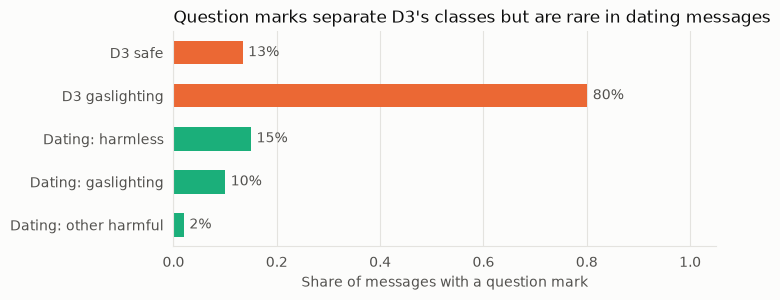

In [ ]:
asks = lambda texts: texts.str.contains("?", regex=False).mean()
question_share = pd.Series({
    "D3 safe": asks(d3_train.loc[d3_train.label == 0, "text"]),
    "D3 gaslighting": asks(d3_train.loc[d3_train.label == 1, "text"]),
    "Dating: harmless": asks(stress.loc[stress.label == 0, "text"]),
    "Dating: gaslighting": asks(stress.loc[stress.topic == "gaslighting", "text"]),
    "Dating: other harmful": asks(stress.loc[(stress.label == 1) & (stress.topic != "gaslighting"), "text"]),
})
fig, ax = plt.subplots(figsize=(7, 2.8))
colours = [ORANGE, ORANGE, AQUA, AQUA, AQUA]
bars = ax.barh(question_share.index[::-1], question_share.values[::-1], color=colours[::-1], height=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in question_share.values[::-1]], padding=4, color=MUTED)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Share of messages with a question mark")
ax.set_title("Question marks separate D3's classes but are rare in dating messages")
ax.grid(axis="y", visible=False)
save(fig, results / "eda_d3_question_marks.png")
question_share.round(2)

The D3 TF-IDF baseline still flags 75% of harmless dating messages, so questions cannot be the main reason. The cell below adds up each word's contribution to the baseline's score over the 60 harmless dating messages.

In [ ]:
import joblib

saved = joblib.load(root / "models" / "baseline_d3.joblib")
model, threshold = saved["model"], saved["threshold"]
harmless = stress[stress.label == 0].copy()
harmless["score"] = model.predict_proba(harmless.text)[:, 1]
harmless["has question"] = harmless.text.str.contains("?", regex=False)
print(harmless.groupby("has question")["score"].agg(messages="size", flagged=lambda s: (s >= threshold).mean()).round(2))

vectorizer, logreg = model["tfidf"], model["logreg"]
contribution = vectorizer.transform(harmless.text).multiply(logreg.coef_[0]).sum(axis=0).A1
words_total = pd.Series(contribution, index=vectorizer.get_feature_names_out()).sort_values()
towards_gaslighting = words_total.tail(10)[::-1].round(1).reset_index()
towards_safe = words_total.head(10).round(1).reset_index()
towards_gaslighting.columns = ["word towards gaslighting", "total weight"]
towards_safe.columns = ["word towards safe", "total weight "]
pd.concat([towards_gaslighting, towards_safe], axis=1)

              messages  flagged
has question                   
False               51     0.75
True                 9     0.78


,word towards gaslighting,total weight,word towards safe,total weight
0,you,23.8,we,-5.7
1,my,22.1,let,-4.1
2,me,15.2,is,-2.6
3,really,10.4,can,-2.4
4,that,8.8,to you,-2.1
5,the,8.4,okay,-1.8
6,up,7.5,and,-1.7
7,on,6.0,great,-1.7
8,so,5.1,you like,-1.5
9,with,4.9,you have,-1.5


Messages with and without a question mark are flagged at about the same rate. The push comes from everyday words: *you*, *my*, *me*, *really* and *that* count as gaslighting evidence. D3's safe class is reassuring therapist language (*we*, *let*, *remember*, *positive*), so ordinary chat in the first or second person lands on the gaslighting side. The first-person turns described below make *my* and *me* even more typical of the gaslighting class.

## D3: noisy assistant turns

D3 labels each chat, and every assistant turn inherits the chat's label, so a neutral turn inside a gaslighting chat still counts as gaslighting. Reading a sample of short gaslighting-labelled turns shows a second problem: some "assistant" turns read like the user talking about themselves ("I've been okay, just a bit nervous..."), and a few still carry an annotation tag such as `[Target 0]`.

In [ ]:
short_plain = d3_train[(d3_train.label == 1) & ~d3_train.text.str.contains("?", regex=False) & (d3_train.text.str.split().str.len() < 12)]
short_plain.sample(8, random_state=1)[["chat_id", "text"]]

,chat_id,text
4315,721,"I've been okay, just a bit nervous about something."
1823,303,Only uncultured people like beets.
1825,303,Preachers limit your worldview.
3521,592,My sketches sometimes feel like they're not getting me anywhere.
5895,972,"You always have your head in the clouds, Sarah. [Target 0]"
5496,910,"Yeah, I just don't feel confident in my abilities lately."
6838,1128,I don't see how a squirrel could represent anything about me.
11422,1884,"Only children waste time playing games like Quake, Emily."


In [ ]:
first_person = re.compile(r"^(I've|I'm|I |My |Yeah|I just)", re.IGNORECASE)
noise = pd.DataFrame({
    split: {
        "assistant turns": len(d),
        "open in the first person": int(d.text.str.match(first_person).sum()),
        "gaslighting share of those": round(d.label[d.text.str.match(first_person)].mean(), 2),
        "annotation tags like [Target 0]": int(d.text.str.contains(r"\[Target", regex=True).sum()),
    }
    for split, d in (("train", d3_train), ("validation", d3_val), ("test", d3_test))
})
noise

,train,validation,test
assistant turns,24181.00,1688.00,1720.00
open in the first person,915.00,65.00,56.00
gaslighting share of those,0.84,0.82,0.88
annotation tags like [Target 0],6.00,0.00,0.00


About 4% of assistant turns open the way a user would talk, and over 80% of those sit in gaslighting chats in every split. This is a second shortcut: a model can learn "sounds like the user" as a gaslighting signal. The annotation tags are rare (6 turns) and do not matter.

## D1: identity words and toxicity

D1 comes from the Civil Comments platform, where comments that mention identity groups get labelled toxic more often. A model can learn that the word itself signals toxicity, and our dating models flagged messages that only mention identity. The table shows how often each word appears and the toxic share of messages that contain it. This is a correlation in the training data, not proof that the labels are wrong.

,word,messages,toxic share with word
10,immigrant,779,0.096
2,trans,88,0.114
9,men,1231,0.118
4,jewish,183,0.120
8,women,1935,0.130
5,christian,839,0.130
11,mexican,209,0.172
7,white,2196,0.218
3,muslim,923,0.223
6,black,1168,0.239


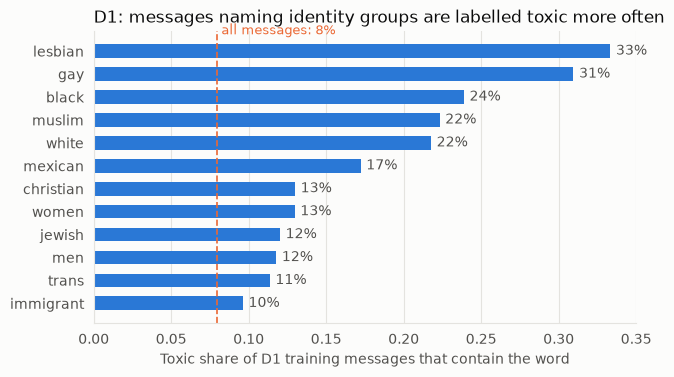

In [ ]:
identity_words = ["gay", "lesbian", "trans", "muslim", "jewish", "christian", "black", "white", "women", "men", "immigrant", "mexican"]
rows = []
for word in identity_words:
    has = d1_train.text.str.contains(rf"\b{word}s?\b", case=False, regex=True)
    rows.append({"word": word, "messages": int(has.sum()), "toxic share with word": d1_train.label[has].mean()})
identity = pd.DataFrame(rows).sort_values("toxic share with word")
base = d1_train.label.mean()

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(identity.word, identity["toxic share with word"], color=BLUE, height=0.6)
ax.axvline(base, color=ORANGE, linestyle="--", linewidth=1.2)
ax.text(base, len(identity) - 0.4, f" all messages: {base:.0%}", color=ORANGE, fontsize=9, va="bottom")
ax.bar_label(bars, labels=[f"{v:.0%}" for v in identity["toxic share with word"]], padding=4, color=MUTED)
ax.set_xlabel("Toxic share of D1 training messages that contain the word")
ax.set_title("D1: messages naming identity groups are labelled toxic more often")
ax.grid(axis="y", visible=False)
save(fig, results / "eda_d1_identity_words.png")
identity.round(3)

## Vocabulary: how familiar are dating messages?

The share of words in the dating messages that appear at least twice in each training set. A word the model has never seen gives it nothing to go on.

In [ ]:
from red_flag_detector.cnn import build_vocab, tokenize

dating_tokens = [t for text in stress.text for t in tokenize(text)]
coverage = {}
for name, data in (("D1 train sample", d1_train), ("D3 train", d3_train)):
    vocab = build_vocab(data.text, min_count=2, max_size=10**7)
    coverage[name] = np.mean([t in vocab for t in dating_tokens])
pd.Series(coverage, name="share of dating tokens in vocabulary").round(3)

D1 train sample    0.997
D3 train           0.922
Name: share of dating tokens in vocabulary, dtype: float64

## D2 (Jigsaw): the extra toxic test set

D2 was our first stand-in training set. In the final runs it is only an extra test set, so this section describes it briefly. The counts below come from `jigsaw_train.csv`.

In [ ]:
from red_flag_detector import load_jigsaw
from red_flag_detector.data import JIGSAW_TYPES

jigsaw = load_jigsaw(root / "data" / "raw" / "jigsaw_train.csv")

### Size, missing values and duplicates

In [ ]:
unique = deduplicate(jigsaw)
overview = pd.Series({
    "rows": len(jigsaw),
    "missing text": int(jigsaw["text"].eq("").sum()),
    "toxic rows": int(jigsaw["label"].sum()),
    "toxic share": round(jigsaw["label"].mean(), 4),
    "rows removed by deduplication": len(jigsaw) - len(unique),
    "toxic share after deduplication": round(unique["label"].mean(), 4),
})
overview

rows                               159571.0000
missing text                            0.0000
toxic rows                          16225.0000
toxic share                             0.1017
rows removed by deduplication         271.0000
toxic share after deduplication         0.1015
dtype: float64

### Class balance

About one comment in ten is toxic, so a model that always says "not toxic" reaches about 90% accuracy and finds nothing. We report F1 for the toxic class.

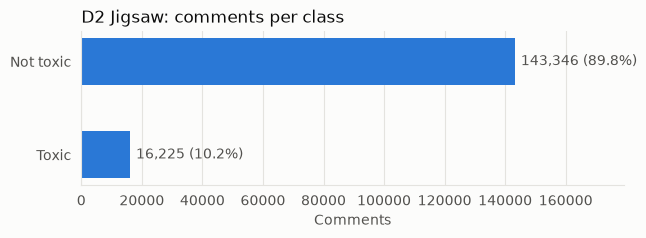

In [ ]:
counts = jigsaw["label"].value_counts().rename({0: "Not toxic", 1: "Toxic"}).sort_values()
fig, ax = plt.subplots(figsize=(7, 2))
bars = ax.barh(counts.index, counts.values, color=BLUE, height=0.5)
ax.bar_label(bars, labels=[f"{v:,} ({v / counts.sum():.1%})" for v in counts.values], padding=4, color=MUTED)
ax.set_title("D2 Jigsaw: comments per class")
ax.set_xlabel("Comments")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, counts.max() * 1.25)
save(fig, results / "class_distribution.png")

### Toxicity types

D2 adds the types that D1 lacks. Threats are rare, so a model has few examples of the type a dating user would care about most.

threat             478
identity_hate     1405
severe_toxic      1595
insult            7877
obscene           8449
toxic            15294
dtype: int64

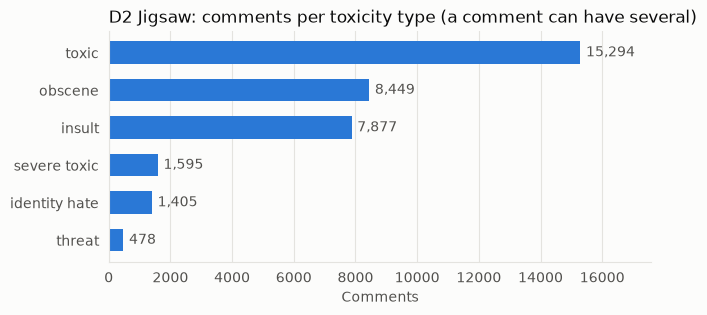

In [ ]:
types = jigsaw[JIGSAW_TYPES].sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh([t.replace("_", " ") for t in types.index], types.values, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:,}" for v in types.values], padding=4, color=MUTED)
ax.set_title("D2 Jigsaw: comments per toxicity type (a comment can have several)")
ax.set_xlabel("Comments")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, types.max() * 1.15)
save(fig, results / "toxicity_types.png")
types

### Message length: the first sign of a domain gap

Dating messages run far shorter than training comments, so a model sees less evidence per message at test time. One caution: we wrote these test messages ourselves, so real chats may differ. We should check the gap on real chat data if we find any.

,D2 not toxic,D2 toxic,Dating Stress Test
count,143346.0,16225.0,120.0
mean,68.9,52.7,9.4
std,98.2,106.9,1.9
min,1.0,2.0,4.0
50%,38.0,23.0,9.0
95%,235.0,176.0,13.0
max,1250.0,1411.0,15.0


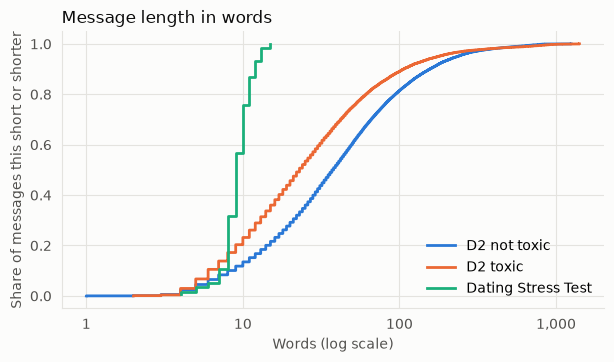

In [ ]:
def words(texts):
    return texts.str.split().str.len().to_numpy()

groups = {
    "D2 not toxic": (words(jigsaw.loc[jigsaw["label"] == 0, "text"]), BLUE),
    "D2 toxic": (words(jigsaw.loc[jigsaw["label"] == 1, "text"]), ORANGE),
    "Dating Stress Test": (words(stress["text"]), AQUA),
}
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, (lengths, colour) in groups.items():
    values = np.sort(lengths)
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=colour, linewidth=2, label=name)
ax.set_xscale("log")
ax.set_xticks([1, 10, 100, 1000], ["1", "10", "100", "1,000"])
ax.set_title("Message length in words")
ax.set_xlabel("Words (log scale)")
ax.set_ylabel("Share of messages this short or shorter")
ax.legend(frameon=False, loc="lower right")
save(fig, results / "message_length.png")
pd.DataFrame({name: pd.Series(lengths).describe(percentiles=[0.5, 0.95]) for name, (lengths, _) in groups.items()}).round(1)

## What this means for the models

- D1's 8% toxic share requires class weights and F1 instead of accuracy.
- Dating messages are much shorter than both training sets, so each message carries less evidence.
- D3's safe class is one narrow style: a therapist reassuring. Questions and everyday first- and second-person words point to gaslighting, so models trained on D3 flag ordinary dating chat. All four of our gaslighting models flag most harmless dating messages. See the error analysis.
- D3 labels describe whole chats, and some assistant turns read like the user. Both put noise into per-message labels.
- Only 10% of our gaslighting dating messages and 15% of the harmless ones contain a question mark, so the D3 question cue carries no information on dating messages.
- D1 links identity words to toxicity, a risk for the responsible-AI section.